## Quantifying Cell-Type-Specific Distribution Shift Between Pseudo-Spatial scRNA-seq and Spatial Transcriptomics Data

#### Load Data

In [ ]:
import pandas as pd
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# load training set
train_adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/syndri_predictions/chromium_breast_train_with_admix_probs.h5ad')
train_adata = ad.concat([train_adata,ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/syndri_predictions/chromium_breast_val_with_admix_probs.h5ad')])

/tmp/ipykernel_2732160/1456183022.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),fontsize=8)


[Text(-10.0, 0, '−10'),
 Text(0.0, 0, '0'),
 Text(10.0, 0, '10'),
 Text(20.0, 0, '20'),
 Text(30.0, 0, '30'),
 Text(40.0, 0, '40'),
 Text(50.0, 0, '50'),
 Text(60.0, 0, '60'),
 Text(70.0, 0, '70')]

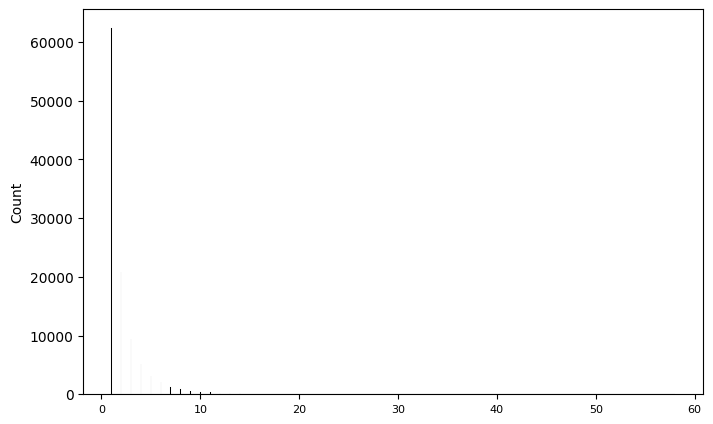

In [45]:
admixed_gene_totals = np.asarray((train_adata.layers['admixed_counts']>0).sum(axis=1)).squeeze()
# print(admixed_gene_totals.shape)
fig,ax = plt.subplots(figsize=(8,5))
sns.histplot(x=admixed_gene_totals,alpha=1,ax=ax,color='black')
ax.set_xticklabels(ax.get_xticklabels(),fontsize=8)

In [2]:
import os
spatial_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/'
files = sorted([f for f in os.listdir(spatial_dir) if f.endswith('1pct.h5ad') and f.startswith('GSM950')])
adata_list = []
for f in files:
    test_adata = ad.read_h5ad(os.path.join(spatial_dir,f))
    test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
    adata_list.append(test_adata)
test_adata = ad.concat(adata_list)
del adata_list
test_adata.obs['cell_type'] = test_adata.obs['harmony_cell_type']


/tmp/ipykernel_2732160/3861014311.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
/tmp/ipykernel_2732160/3861014311.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
/tmp/ipykernel_2732160/3861014311.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and sile

In [10]:
# load single ST tissue
gene_adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/GSM9509174_breast_breast_B1_B1_3_rctd_annotated_dropout_1pct.h5ad')

# ensembl to gene name mapping
gene_dict = dict(zip(gene_adata.var.index,gene_adata.var.feature_name))
del gene_adata

In [11]:
# add admixture
train_adata.layers['raw+admixed'] = train_adata.X + train_adata.layers['admixed_counts']

In [12]:
import numpy as np
import pandas as pd
import scipy.sparse as sp


def get_matrix(adata, obs_mask, genes, layer=None):
    """
    Extract an AnnData matrix for selected cells and genes.

    layer=None
        -> use adata.X

    layer="admixed_counts"
        -> use adata.layers["admixed_counts"]
    """
    adata_subset = adata[obs_mask, genes]

    if layer is None:
        return adata_subset.X

    if layer not in adata.layers:
        raise ValueError(
            f"Layer '{layer}' not found. "
            f"Available layers: {list(adata.layers.keys())}"
        )

    return adata_subset.layers[layer]


def detection_frequency(X):
    """
    Fraction of cells with expression > 0 for each gene.
    Works for dense or sparse matrices.
    """
    if sp.issparse(X):
        return np.asarray(
            (X > 0).mean(axis=0)
        ).ravel()

    X = np.asarray(X)
    return (X > 0).mean(axis=0)


def compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer=None,
    test_layer=None,
    min_cells=1,
):
    """
    Compare per-gene detection frequencies between train and test
    separately for every cell type represented in both datasets.

    Parameters
    ----------
    train_layer : str or None
        None uses train_adata.X.
        For example, "admixed_counts" uses
        train_adata.layers["admixed_counts"].

    test_layer : str or None
        Same behavior for test_adata. Defaults to .X.

    min_cells : int
        Require at least this many cells of a cell type in both
        train and test.
    """

    # Genes available in both datasets
    common_genes = train_adata.var_names.intersection(
        test_adata.var_names
    )

    train_labels = (
        train_adata.obs[cell_type_col]
        .astype("string")
    )

    test_labels = (
        test_adata.obs[cell_type_col]
        .astype("string")
    )

    # Cell types represented in both train and test
    common_cell_types = sorted(
        set(train_labels.dropna())
        & set(test_labels.dropna())
    )

    results = []

    for cell_type in common_cell_types:

        train_mask = train_labels.eq(cell_type).fillna(False).to_numpy()
        test_mask = test_labels.eq(cell_type).fillna(False).to_numpy()

        n_train = train_mask.sum()
        n_test = test_mask.sum()

        if n_train < min_cells or n_test < min_cells:
            continue

        train_X = get_matrix(
            train_adata,
            train_mask,
            common_genes,
            layer=train_layer,
        )

        test_X = get_matrix(
            test_adata,
            test_mask,
            common_genes,
            layer=test_layer,
        )

        train_detection = detection_frequency(train_X)
        test_detection = detection_frequency(test_X)

        cell_type_df = pd.DataFrame({
            "cell_type": cell_type,
            "gene": common_genes,
            "n_train": n_train,
            "n_test": n_test,
            "train_detection": train_detection,
            "test_detection": test_detection,
        })
        cell_type_df['gene_name'] = cell_type_df['gene'].map(gene_dict)

        cell_type_df["detection_delta"] = (
            cell_type_df["test_detection"]
            - cell_type_df["train_detection"]
        )

        cell_type_df["abs_detection_delta"] = (
            cell_type_df["detection_delta"].abs()
        )

        results.append(cell_type_df)

    return pd.concat(
        results,
        ignore_index=True,
    )

raw_detection_df = compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer=None,              # train .X
    test_layer=None,               # test .X
)

admixed_detection_df = compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer="raw+admixed",  # train admixed counts
    test_layer=None,               # test .X
)

In [13]:
admixed_detection_df

,cell_type,gene,n_train,n_test,train_detection,test_detection,gene_name,detection_delta,abs_detection_delta
0,"CD4-positive, alpha-beta memory T cell",ENSG00000121270,1946,1180,0.190647,0.042373,ABCC11,-0.148275,0.148275
1,"CD4-positive, alpha-beta memory T cell",ENSG00000107796,1946,1180,0.007708,0.420339,ACTA2,0.412631,0.412631
2,"CD4-positive, alpha-beta memory T cell",ENSG00000163017,1946,1180,0.000000,0.188136,ACTG2,0.188136,0.188136
3,"CD4-positive, alpha-beta memory T cell",ENSG00000168615,1946,1180,0.011305,0.194915,ADAM9,0.183610,0.183610
4,"CD4-positive, alpha-beta memory T cell",ENSG00000123146,1946,1180,0.210689,0.377966,ADGRE5,0.167278,0.167278
...,...,...,...,...,...,...,...,...,...
4150,smooth muscle cell,ENSG00000110799,7891,6463,0.001774,0.035278,VWF,0.033504,0.033504
4151,smooth muscle cell,ENSG00000140105,7891,6463,0.025979,0.206870,WARS,0.180891,0.180891
4152,smooth muscle cell,ENSG00000148516,7891,6463,0.410594,0.380783,ZEB1,-0.029811,0.029811
4153,smooth muscle cell,ENSG00000169554,7891,6463,0.289190,0.514622,ZEB2,0.225431,0.225431


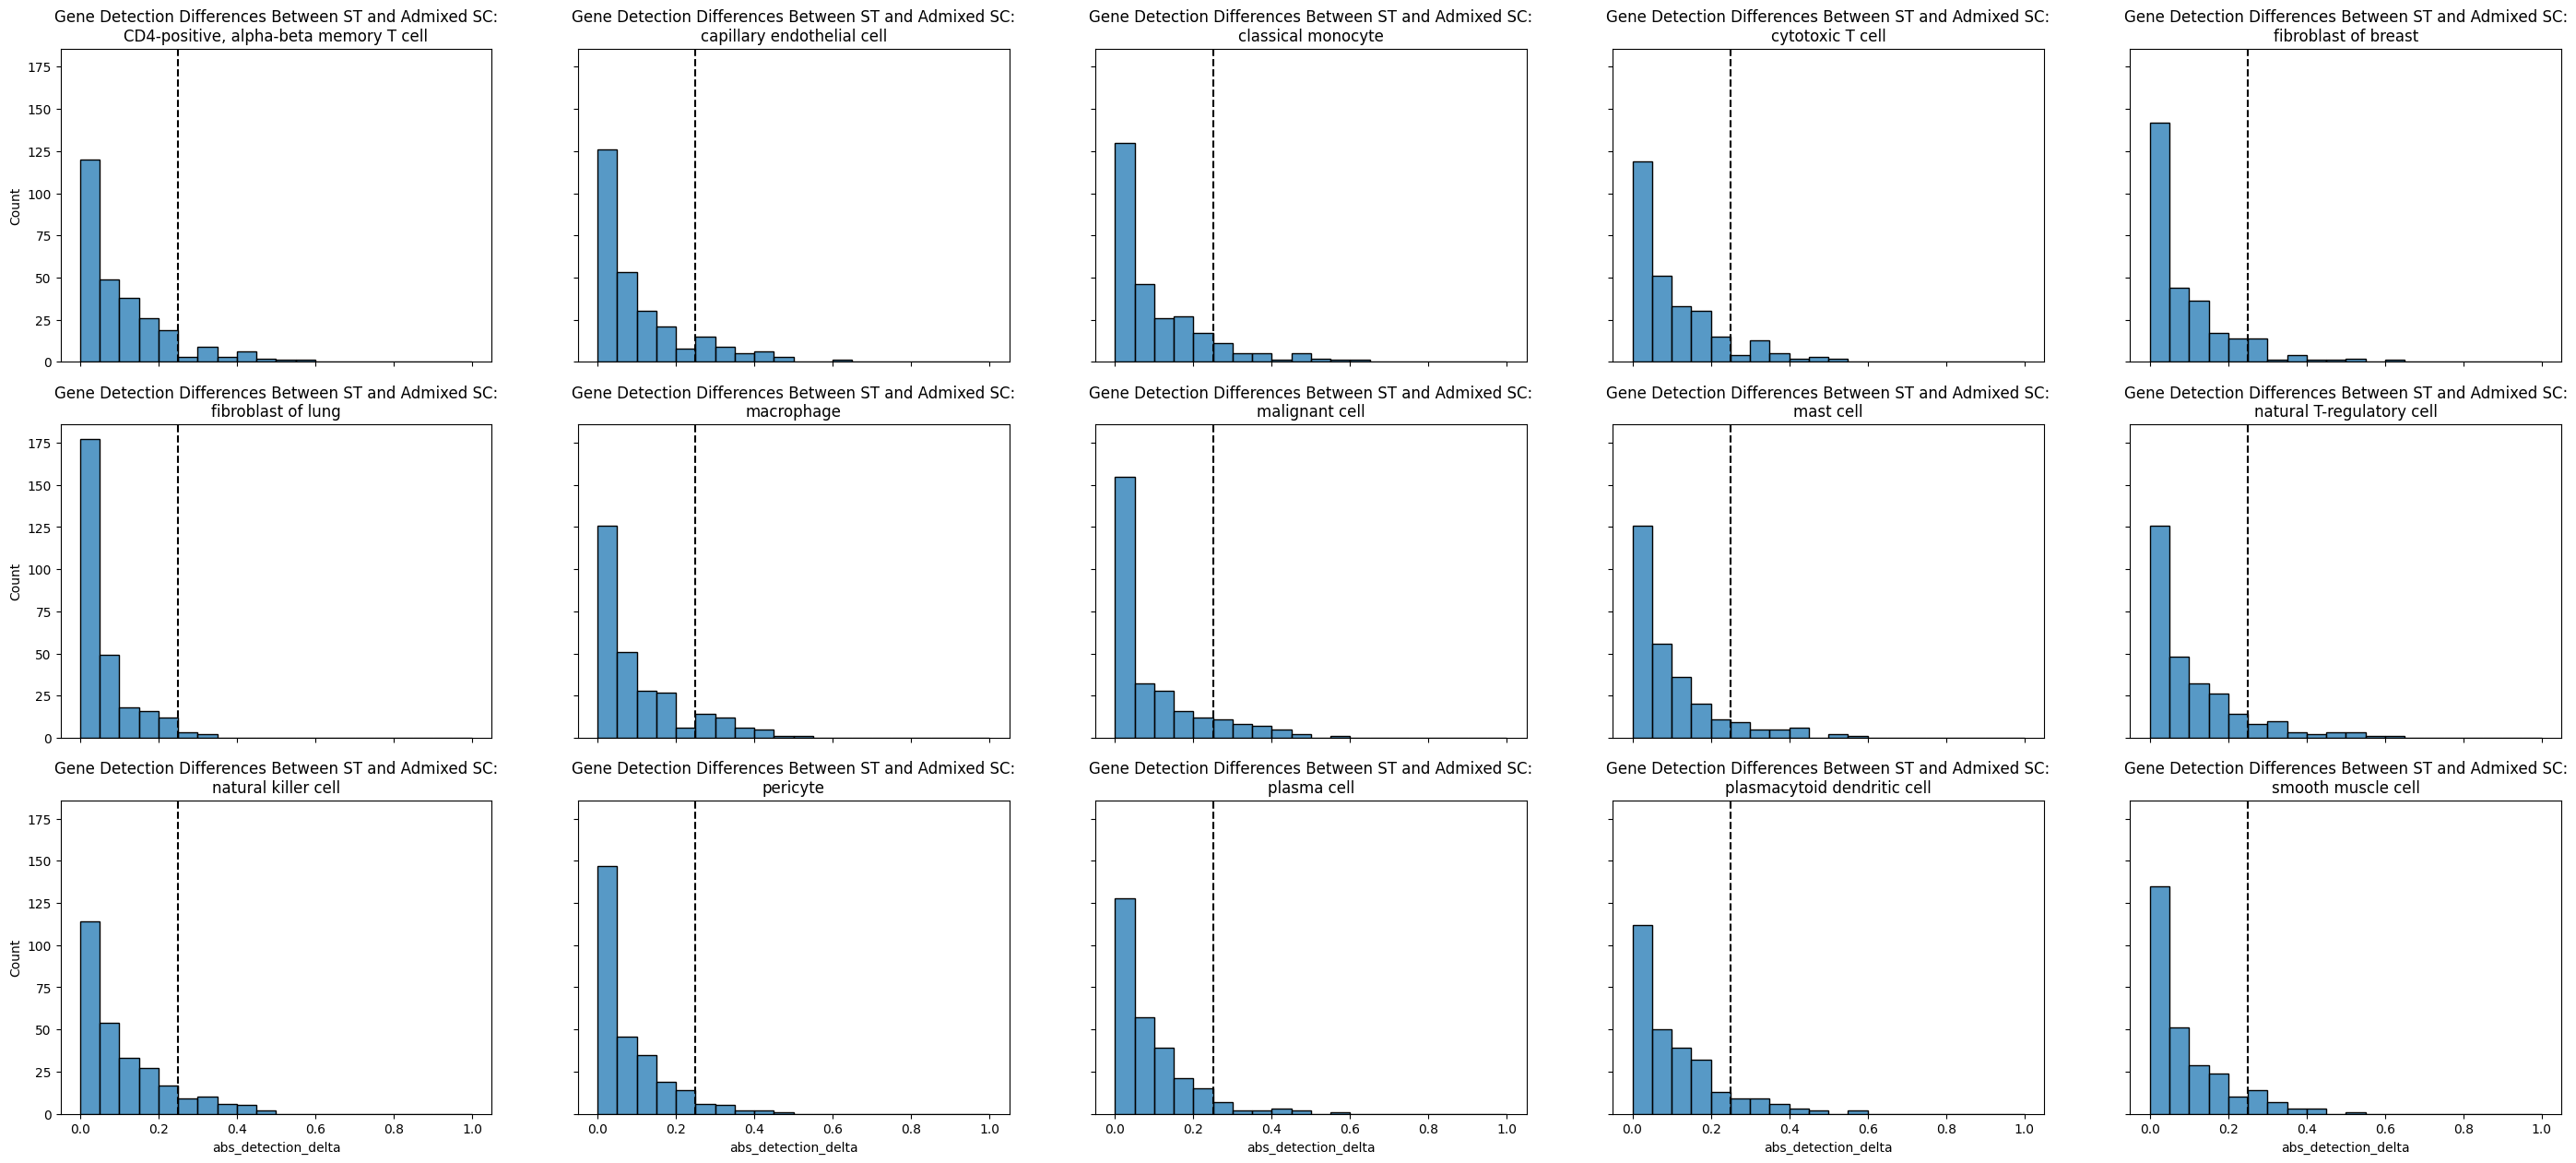

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
admixed_detection_df#[admixed_detection_df['cell_type'].str.contains('fibroblast')].sort_values(by=['cell_type','abs_detection_delta'],ascending=[True,False])
NROWS=3
NCOLS=5
cell_types = sorted(admixed_detection_df['cell_type'].unique().tolist())
fig,axes= plt.subplots(nrows=NROWS,ncols=NCOLS,figsize=(7*NCOLS,5*NROWS),sharex=True,sharey=True)
for i,ct in enumerate(cell_types):
    ax = axes.flat[i]
    sns.histplot(admixed_detection_df[(admixed_detection_df['cell_type']==ct)],x='abs_detection_delta',ax=ax,bins=np.arange(0,1.01,0.05))
    ax.set_title(f'Gene Detection Differences Between ST and Admixed SC:\n{ct}')
    ax.axvline(x=0.25,c='black',linestyle='--')

In [15]:
detection_summary = (
    admixed_detection_df
    .groupby("cell_type")
    .agg(
        median_abs_delta=("abs_detection_delta", "median"),
        mean_abs_delta=("abs_detection_delta", "mean"),
        q90_abs_delta=("abs_detection_delta", lambda x: x.quantile(0.90)),
        q95_abs_delta=("abs_detection_delta", lambda x: x.quantile(0.95)),
        max_abs_delta=("abs_detection_delta", "max"),
        frac_gt_0_10=("abs_detection_delta", lambda x: (x > 0.10).mean()),
        frac_gt_0_25=("abs_detection_delta", lambda x: (x > 0.25).mean()),
        frac_gt_0_50=("abs_detection_delta", lambda x: (x > 0.50).mean()),
    )
)

detection_summary

admixed_detection_df["direction"] = np.where(
    admixed_detection_df["detection_delta"] > 0,
    "Higher in ST",
    "Higher in training SC",
)

large_shifts = admixed_detection_df[
    admixed_detection_df["abs_detection_delta"] > 0.25
]

pd.crosstab(
    large_shifts["cell_type"],
    large_shifts["direction"],
)

direction,Higher in ST,Higher in training SC
cell_type,,
"CD4-positive, alpha-beta memory T cell",25,0
capillary endothelial cell,38,1
classical monocyte,31,0
cytotoxic T cell,29,0
fibroblast of breast,24,0
fibroblast of lung,5,0
macrophage,36,3
malignant cell,29,5
mast cell,26,2


In [16]:
comparison_df = raw_detection_df.merge(
    admixed_detection_df,
    on=["cell_type", "gene"],
    suffixes=("_raw", "_admixed"),
)

comparison_df["change_in_abs_shift"] = (
    comparison_df["abs_detection_delta_admixed"]
    - comparison_df["abs_detection_delta_raw"]
)

cell_type_comparison = (
    comparison_df
    .groupby("cell_type")
    .agg(
        raw_mean_abs_shift=(
            "abs_detection_delta_raw",
            "mean",
        ),
        admixed_mean_abs_shift=(
            "abs_detection_delta_admixed",
            "mean",
        ),
        mean_change=(
            "change_in_abs_shift",
            "mean",
        ),
        raw_median_abs_shift=(
            "abs_detection_delta_raw",
            "median",
        ),
        admixed_median_abs_shift=(
            "abs_detection_delta_admixed",
            "median",
        ),
    )
)

cell_type_comparison["relative_change"] = (
    cell_type_comparison["admixed_mean_abs_shift"]
    / cell_type_comparison["raw_mean_abs_shift"]
)

cell_type_comparison.sort_values("mean_change")


cell_type_comparison = (
    comparison_df
    .groupby("cell_type")
    .agg(
        raw_mean_abs_shift=(
            "abs_detection_delta_raw",
            "mean",
        ),
        admixed_mean_abs_shift=(
            "abs_detection_delta_admixed",
            "mean",
        ),
        mean_change=(
            "change_in_abs_shift",
            "mean",
        ),
        raw_median_abs_shift=(
            "abs_detection_delta_raw",
            "median",
        ),
        admixed_median_abs_shift=(
            "abs_detection_delta_admixed",
            "median",
        ),
    )
)

cell_type_comparison["relative_change"] = (
    cell_type_comparison["admixed_mean_abs_shift"]
    / cell_type_comparison["raw_mean_abs_shift"]
)

cell_type_comparison.sort_values("mean_change")

,raw_mean_abs_shift,admixed_mean_abs_shift,mean_change,raw_median_abs_shift,admixed_median_abs_shift,relative_change
cell_type,,,,,,
malignant cell,0.099982,0.091184,-0.008798,0.048143,0.037698,0.912007
plasma cell,0.094054,0.088508,-0.005547,0.061981,0.057915,0.941028
macrophage,0.109024,0.103581,-0.005442,0.061936,0.056767,0.950080
capillary endothelial cell,0.108576,0.103505,-0.005071,0.063527,0.055712,0.953295
natural killer cell,0.113809,0.109055,-0.004754,0.081272,0.076293,0.958229
classical monocyte,0.109607,0.104930,-0.004677,0.059480,0.055472,0.957328
smooth muscle cell,0.095923,0.091265,-0.004658,0.058089,0.051351,0.951441
fibroblast of lung,0.061657,0.057029,-0.004628,0.033027,0.029679,0.924933
cytotoxic T cell,0.108604,0.104081,-0.004523,0.072827,0.068216,0.958355


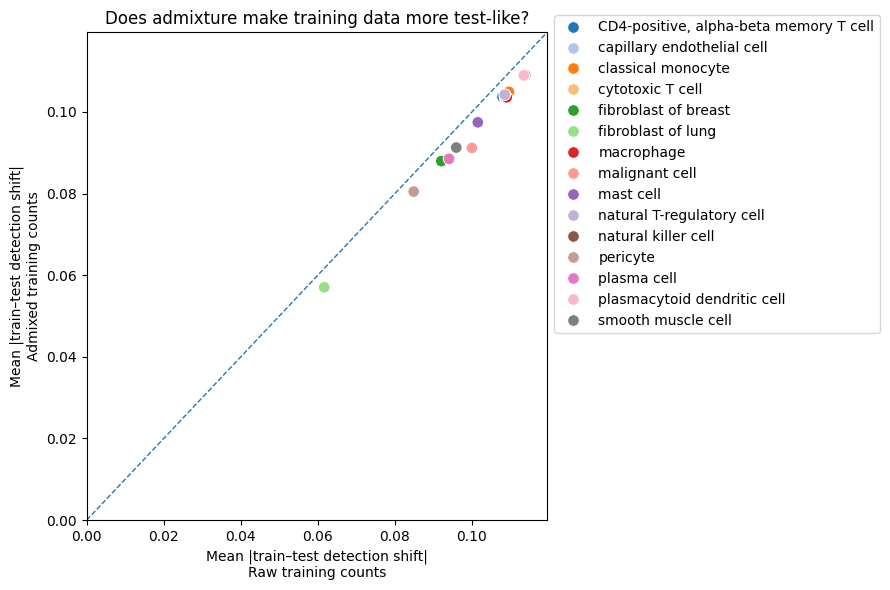

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=cell_type_comparison.reset_index(),
    x="raw_mean_abs_shift",
    y="admixed_mean_abs_shift",
    s=70,
    ax=ax,
    hue='cell_type',
    palette='tab20',
)

lims = [
    0,
    max(
        cell_type_comparison["raw_mean_abs_shift"].max(),
        cell_type_comparison["admixed_mean_abs_shift"].max(),
    ) * 1.05,
]

ax.plot(
    lims,
    lims,
    linestyle="--",
    linewidth=1,
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel(
    "Mean |train–test detection shift|\nRaw training counts"
)

ax.set_ylabel(
    "Mean |train–test detection shift|\nAdmixed training counts"
)

ax.set_title(
    "Does admixture make training data more test-like?"
)
ax.legend(bbox_to_anchor=(1,1.05))
fig.tight_layout()

In [18]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

from scipy.stats import wasserstein_distance


def get_gene_values(
    adata,
    cell_mask,
    gene,
    layer=None,
):
    """
    Get expression values for one gene across selected cells.
    """

    adata_subset = adata[cell_mask, [gene]]

    if layer is None:
        X = adata_subset.X
    else:
        X = adata_subset.layers[layer]

    if sp.issparse(X):
        values = X.toarray().ravel()
    else:
        values = np.asarray(X).ravel()

    return values


def characterize_detected_expression(
    train_adata,
    test_adata,
    detection_df,
    cell_type_col="cell_type",
    train_layer="admixed_counts",
    test_layer=None,
    detection_threshold=0.25,
):
    """
    Characterize expression conditional on detection for genes
    with large train-test detection differences.
    """

    # Only genes with large detection-frequency shifts
    shifted_genes = detection_df.loc[
        detection_df["abs_detection_delta"] > detection_threshold
    ].copy()

    train_labels = (
        train_adata.obs[cell_type_col]
        .astype("string")
    )

    test_labels = (
        test_adata.obs[cell_type_col]
        .astype("string")
    )

    rows = []

    for _, detection_row in shifted_genes.iterrows():

        cell_type = detection_row["cell_type"]
        gene = detection_row["gene"]

        train_mask = (
            train_labels.eq(cell_type)
            .fillna(False)
            .to_numpy()
        )

        test_mask = (
            test_labels.eq(cell_type)
            .fillna(False)
            .to_numpy()
        )

        train_values = get_gene_values(
            train_adata,
            train_mask,
            gene,
            layer=train_layer,
        )

        test_values = get_gene_values(
            test_adata,
            test_mask,
            gene,
            layer=test_layer,
        )

        # Conditional on detection
        train_nonzero = train_values[
            train_values > 0
        ]

        test_nonzero = test_values[
            test_values > 0
        ]

        if (
            len(train_nonzero) == 0
            or len(test_nonzero) == 0
        ):
            continue

        # log1p distributions for a more stable
        # comparison of count magnitudes
        train_log = np.log1p(train_nonzero)
        test_log = np.log1p(test_nonzero)

        rows.append({
            "cell_type": cell_type,
            "gene": gene,

            # Existing detection information
            "train_detection":
                detection_row["train_detection"],
            "test_detection":
                detection_row["test_detection"],
            "detection_delta":
                detection_row["detection_delta"],
            "abs_detection_delta":
                detection_row["abs_detection_delta"],

            # Number of detected cells
            "n_detected_train": len(train_nonzero),
            "n_detected_test": len(test_nonzero),

            # Raw count summaries
            "train_mean_nonzero":
                np.mean(train_nonzero),
            "test_mean_nonzero":
                np.mean(test_nonzero),

            "train_median_nonzero":
                np.median(train_nonzero),
            "test_median_nonzero":
                np.median(test_nonzero),

            "train_q25_nonzero":
                np.quantile(train_nonzero, 0.25),
            "train_q75_nonzero":
                np.quantile(train_nonzero, 0.75),

            "test_q25_nonzero":
                np.quantile(test_nonzero, 0.25),
            "test_q75_nonzero":
                np.quantile(test_nonzero, 0.75),

            # Conditional expression difference
            "median_log1p_train":
                np.median(train_log),
            "median_log1p_test":
                np.median(test_log),

            "median_log1p_delta":
                np.median(test_log)
                - np.median(train_log),

            # Full conditional-distribution difference
            "wasserstein_log1p":
                wasserstein_distance(
                    train_log,
                    test_log,
                ),
        })

    return pd.DataFrame(rows)

expression_shift_df = characterize_detected_expression(
    train_adata,
    test_adata,
    admixed_detection_df,
    cell_type_col="cell_type",
    train_layer="raw+admixed",
    test_layer=None,
    detection_threshold=0.25,
)

expression_shift_df.head()

,cell_type,gene,train_detection,test_detection,detection_delta,abs_detection_delta,n_detected_train,n_detected_test,train_mean_nonzero,test_mean_nonzero,train_median_nonzero,test_median_nonzero,train_q25_nonzero,train_q75_nonzero,test_q25_nonzero,test_q75_nonzero,median_log1p_train,median_log1p_test,median_log1p_delta,wasserstein_log1p
0,"CD4-positive, alpha-beta memory T cell",ENSG00000107796,0.007708,0.420339,0.412631,0.412631,15,496,7.800000,2.296371,3.0,1.0,1.0,10.0,1.0,3.0,1.386294,0.693147,-6.931472e-01,0.604701
1,"CD4-positive, alpha-beta memory T cell",ENSG00000204472,0.006680,0.311864,0.305184,0.305184,13,368,2.153846,1.489130,1.0,1.0,1.0,3.0,1.0,2.0,0.693147,0.693147,-1.904654e-09,0.182513
2,"CD4-positive, alpha-beta memory T cell",ENSG00000091986,0.022097,0.427966,0.405869,0.405869,43,505,5.395349,2.489109,1.0,2.0,1.0,7.5,1.0,3.0,0.693147,1.098612,4.054651e-01,0.383803
3,"CD4-positive, alpha-beta memory T cell",ENSG00000198821,0.067318,0.438983,0.371665,0.371665,131,518,1.633588,1.567568,2.0,1.0,1.0,2.0,1.0,2.0,1.098612,0.693147,-4.054651e-01,0.157503
4,"CD4-positive, alpha-beta memory T cell",ENSG00000198851,0.480473,0.745763,0.265290,0.265290,935,880,1.703743,3.127273,2.0,3.0,1.0,2.0,1.0,4.0,1.098612,1.386294,2.876821e-01,0.336009


In [19]:
cell_type_expression_summary = (
    expression_shift_df
    .groupby("cell_type")
    .agg(
        n_large_detection_shift_genes=(
            "gene",
            "size",
        ),
        median_expression_delta=(
            "median_log1p_delta",
            "median",
        ),
        median_abs_expression_delta=(
            "median_log1p_delta",
            lambda x: np.median(np.abs(x)),
        ),
        median_wasserstein=(
            "wasserstein_log1p",
            "median",
        ),
        fraction_higher_expression_in_ST=(
            "median_log1p_delta",
            lambda x: (x > 0).mean(),
        ),
    )
)

cell_type_expression_summary

,n_large_detection_shift_genes,median_expression_delta,median_abs_expression_delta,median_wasserstein,fraction_higher_expression_in_ST
cell_type,,,,,
"CD4-positive, alpha-beta memory T cell",25,-1.904654e-09,4.054651e-01,0.291857,0.280000
capillary endothelial cell,39,-1.904654e-09,2.231436e-01,0.186117,0.333333
classical monocyte,31,-1.904654e-09,4.054651e-01,0.230050,0.258065
cytotoxic T cell,29,-1.904654e-09,1.983409e-08,0.219408,0.137931
fibroblast of breast,24,-1.904654e-09,1.904654e-09,0.202515,0.333333
fibroblast of lung,5,-1.904654e-09,1.904654e-09,0.081854,0.200000
macrophage,39,-1.904654e-09,2.231435e-01,0.229775,0.358974
malignant cell,34,3.465736e-01,4.054651e-01,0.319800,0.588235
mast cell,28,-1.182170e-08,3.465736e-01,0.249646,0.142857


upper_right     28.361858
upper_left       0.244499
lower_left       3.667482
lower_right     67.726161
n              409.000000
dtype: float64

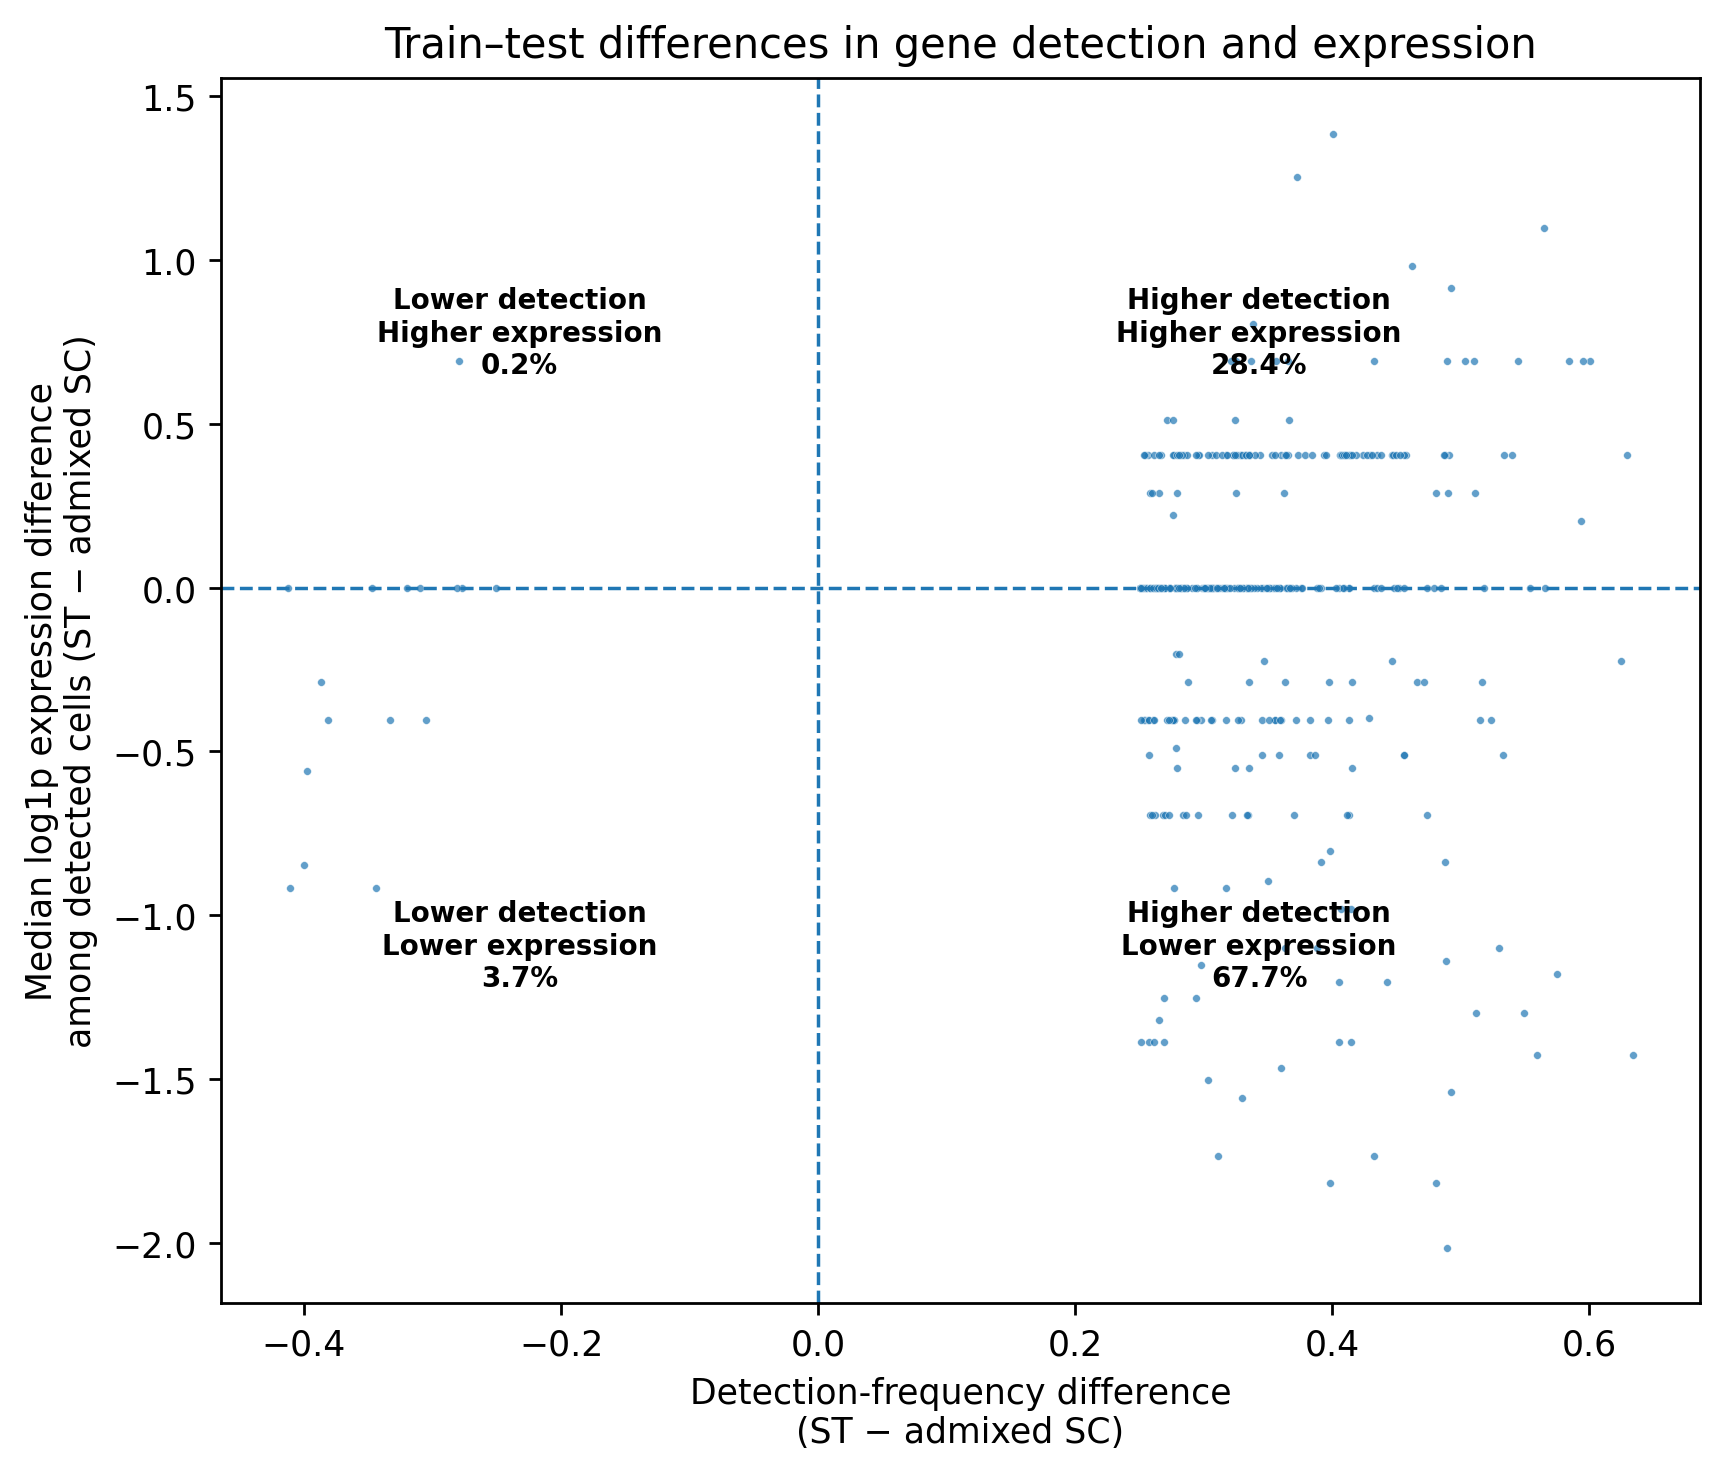

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, ax = plt.subplots(figsize=(7, 6),dpi=250)

sns.scatterplot(
    data=expression_shift_df,
    x="detection_delta",
    y="median_log1p_delta",
    # hue="cell_type",
    alpha=0.7,
    ax=ax,
    s=5,
    # palette="tab20",
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Detection-frequency difference\n(ST − admixed SC)"
)

ax.set_ylabel(
    "Median log1p expression difference\n"
    "among detected cells (ST − admixed SC)"
)

ax.set_title(
    "Train–test differences in gene detection and expression"
)


# ------------------------------------------------------------
# Calculate quadrant percentages
# ------------------------------------------------------------

x = expression_shift_df["detection_delta"]
y = expression_shift_df["median_log1p_delta"]

quadrants = {
    "upper_right": (x > 0) & (y > 0),
    "upper_left":  (x < 0) & (y > 0),
    "lower_left":  (x < 0) & (y < 0),
    "lower_right": (x > 0) & (y < 0),
}

n_total = len(expression_shift_df)

quadrant_pct = {
    name: 100 * mask.sum() / n_total
    for name, mask in quadrants.items()
}


# ------------------------------------------------------------
# Annotate quadrants
# ------------------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

positions = {
    "upper_left": (
        (xmin + 0) / 2,
        (0 + ymax) / 2,
    ),
    "upper_right": (
        (0 + xmax) / 2,
        (0 + ymax) / 2,
    ),
    "lower_left": (
        (xmin + 0) / 2,
        (ymin + 0) / 2,
    ),
    "lower_right": (
        (0 + xmax) / 2,
        (ymin + 0) / 2,
    ),
}

quadrant_labels = {
    "upper_right": "Higher detection\nHigher expression",
    "upper_left": "Lower detection\nHigher expression",
    "lower_left": "Lower detection\nLower expression",
    "lower_right": "Higher detection\nLower expression",
}

for quadrant, (xpos, ypos) in positions.items():
    ax.text(
        xpos,
        ypos,
        (
            f"{quadrant_labels[quadrant]}\n"
            f"{quadrant_pct[quadrant]:.1f}%"
        ),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
    )

fig.tight_layout()


# Optional numeric summary
pd.Series({
    **quadrant_pct,
    "n": n_total,
})

In [48]:
test_nonzero = test_adata.X.copy()
# Within ST cells where the gene is detected
frac_st_count_1 = np.mean(test_nonzero == 1)
frac_st_count_le2 = np.mean(test_nonzero <= 2)

train_nonzero = train_adata.layers['raw+admixed'].copy()
# Within training cells where detected
frac_train_count_1 = np.mean(train_nonzero == 1)
frac_train_count_le2 = np.mean(train_nonzero <= 2)

print(frac_st_count_1,frac_st_count_le2)
print(frac_train_count_1,frac_train_count_le2)

/tmp/ipykernel_2732160/1420354292.py:4: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using <= is inefficient, try using > instead.
  frac_st_count_le2 = np.mean(test_nonzero <= 2)
/tmp/ipykernel_2732160/1420354292.py:9: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using <= is inefficient, try using > instead.
  frac_train_count_le2 = np.mean(train_nonzero <= 2)


0.08988830637031807 0.9548531141335823
0.04748286736048063 0.973399632732308


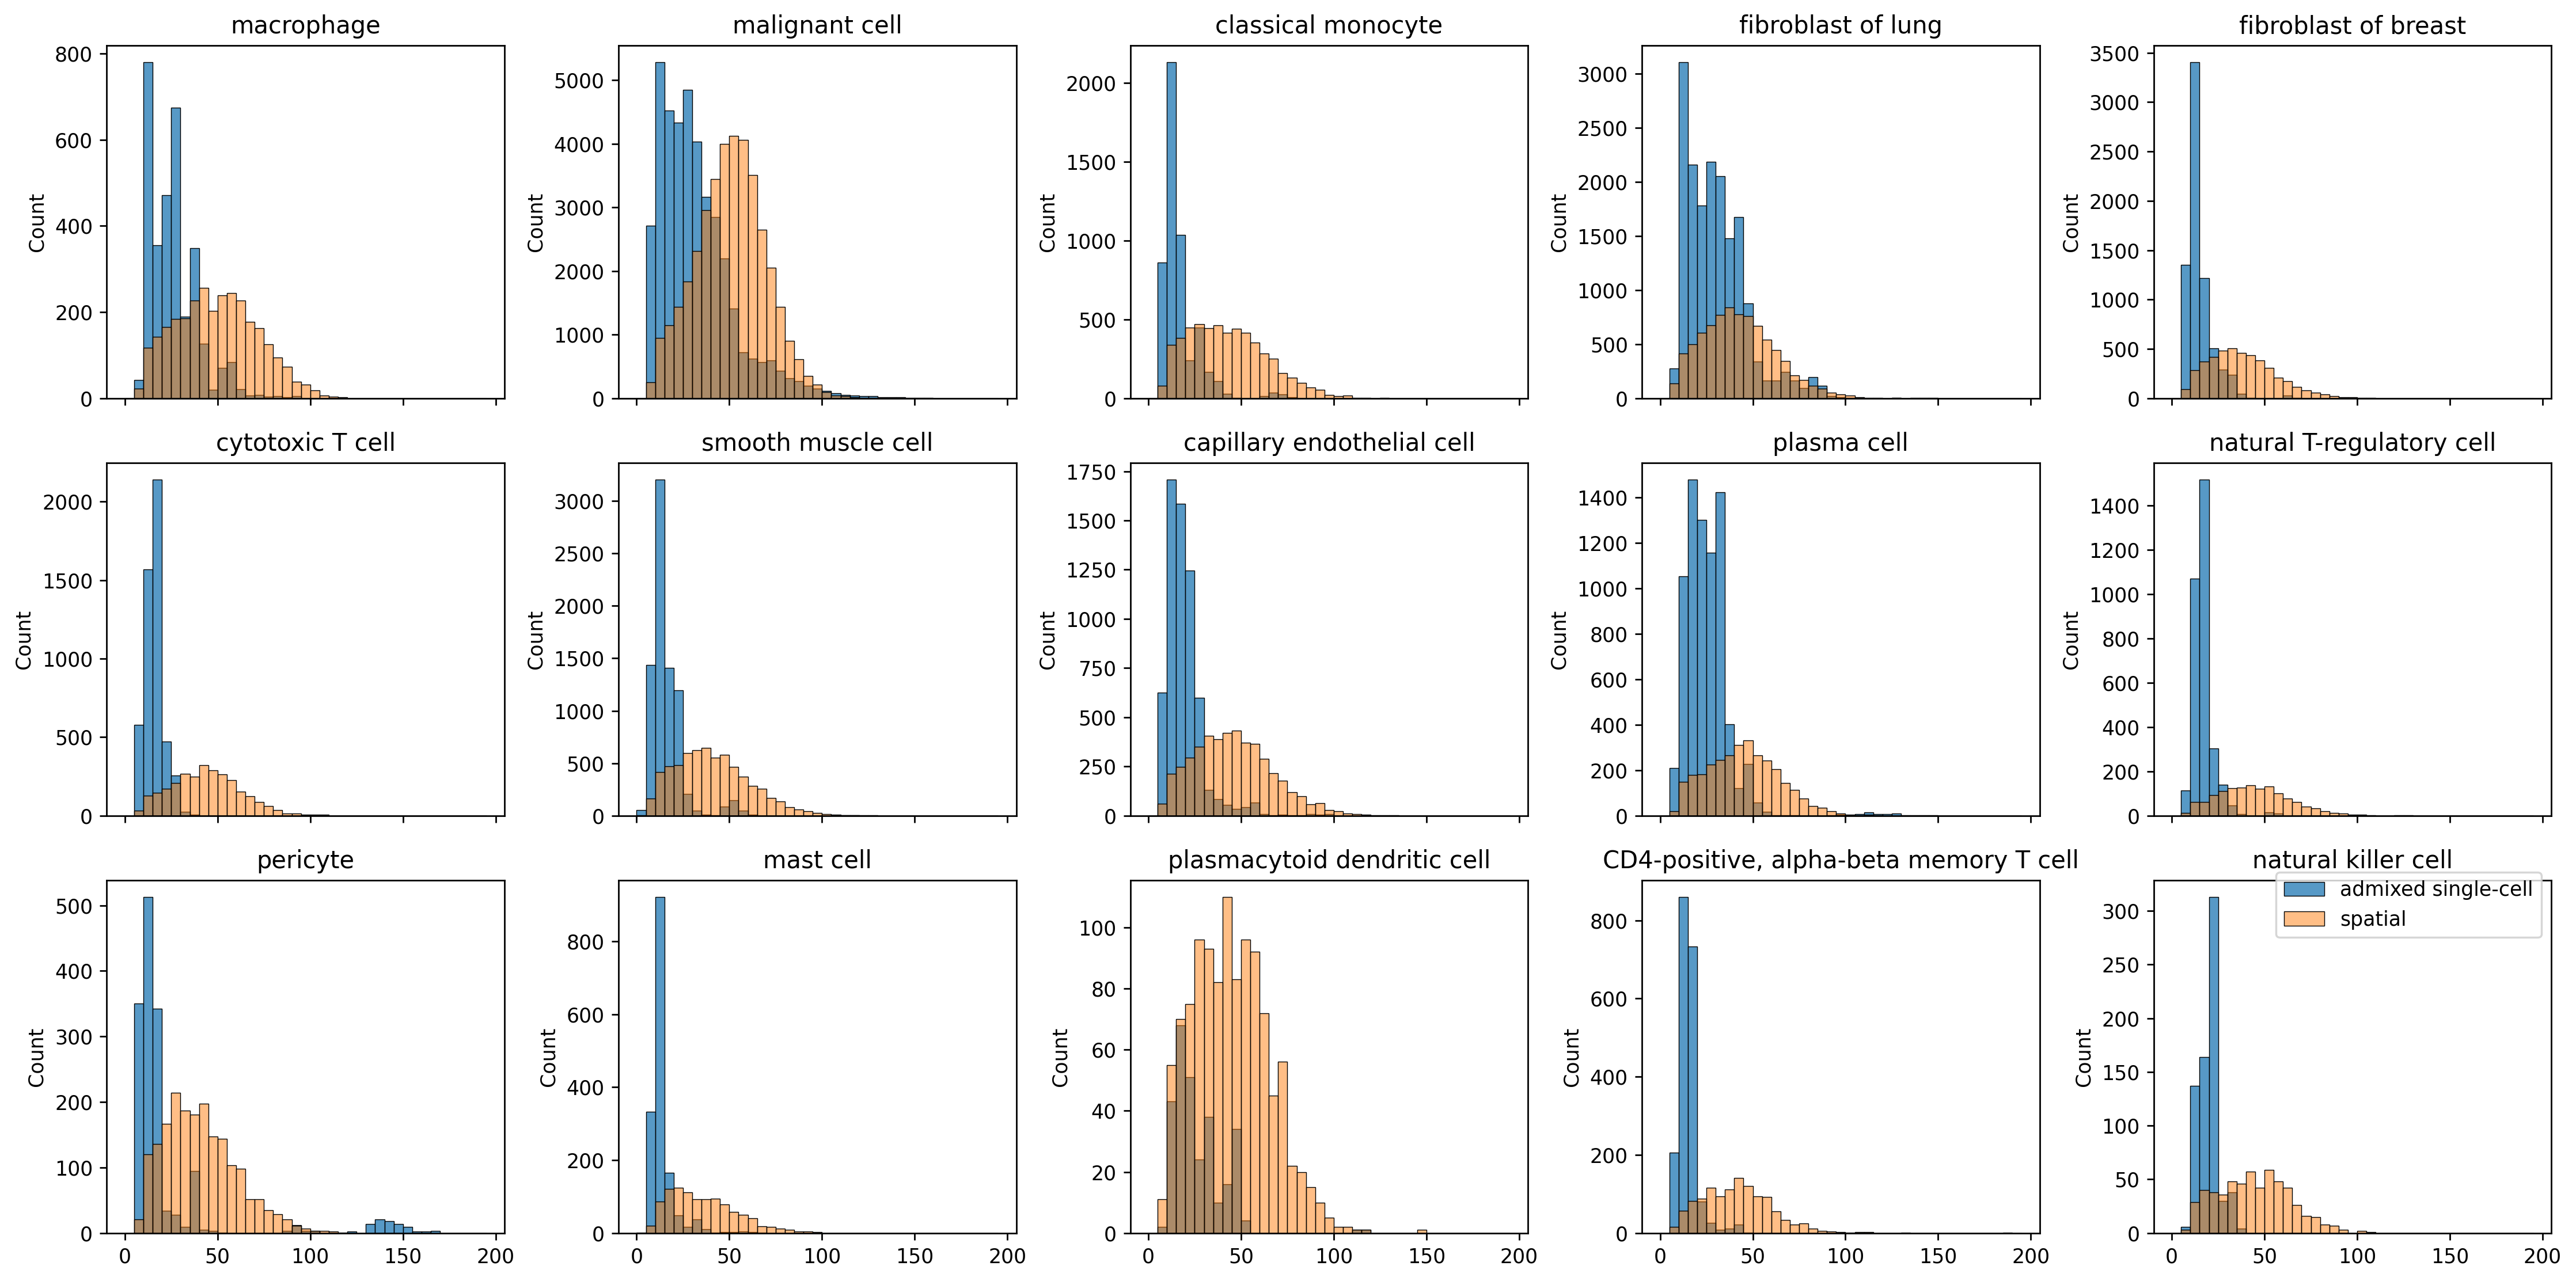

In [68]:
train_n_detected = np.asarray((train_adata.layers['raw+admixed']> 0).sum(axis=1)).ravel()
test_n_detected = np.asarray((test_adata.X > 0).sum(axis=1)).ravel()

cell_types = train_adata.obs['cell_type'].unique().tolist()
fig,axes = plt.subplots(nrows=3,ncols=5,figsize=(18,9),sharex=True,dpi=250)
for i,ax in enumerate(axes.flat):
    train_n_detected = np.asarray((train_adata[train_adata.obs['cell_type']==cell_types[i]].layers['raw+admixed']> 0).sum(axis=1)).ravel()
    test_n_detected = np.asarray((test_adata[test_adata.obs['cell_type']==cell_types[i]].X > 0).sum(axis=1)).ravel()
    sns.histplot(x=train_n_detected,ax=ax,label='admixed single-cell',bins=np.arange(0,200,5))
    sns.histplot(x=test_n_detected,alpha=0.5,ax=ax,label='spatial',bins=np.arange(0,200,5))
    ax.set_title(cell_types[i])
    if i ==14:
        ax.legend(bbox_to_anchor=(1,1.05))

fig.tight_layout()

In [21]:
expression_shift_df["pattern"] = np.select(
    [
        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] > 0),

        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] == 0),

        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] < 0),

        (expression_shift_df["detection_delta"] < 0)
        & (expression_shift_df["median_log1p_delta"] > 0),

        (expression_shift_df["detection_delta"] < 0)
        & (expression_shift_df["median_log1p_delta"] < 0),
    ],
    [
        "More detected + higher in ST",
        "More detected + same in ST",
        "More detected + lower in ST",
        "Less detected + higher in ST",
        "Less detected + lower in ST",
    ],
    default="Other",
)

expression_shift_df["pattern"].value_counts()

pattern
More detected + lower in ST     277
More detected + higher in ST    116
Less detected + lower in ST      15
Less detected + higher in ST      1
Name: count, dtype: int64